# 03 – Model comparison

Comparing learned models with the baselines from `02_baseline.ipynb`, using the same split, preprocessing and cross-validation. The test set stays closed in this notebook and is only used once, on the final model.

## 1. Setup

In [1]:
import sys

import matplotlib.pyplot as plt
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, fbeta_score, precision_score, f1_score
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

SEED = 42
TEST_SIZE = 0.2
N_FOLDS = 5

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.13.11
pandas: 3.0.6
scikit-learn: 1.9.1


In [2]:
df = pd.read_csv("../data/ai4i2020.csv")

target = "Machine failure"
drop_cols = ["UDI", "Product ID", "TWF", "HDF", "PWF", "OSF", "RNF"]

X = df.drop(columns=drop_cols + [target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED
)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Failures in train:", y_train.sum(), "Failures in test:", y_test.sum())

Train: (8000, 6) Test: (2000, 6)
Failures in train: 271 Failures in test: 68


In [3]:
numeric_cols = ["Air temperature [K]", "Process temperature [K]",
                "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
categorical_cols = ["Type"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
])

cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

scoring = {
    "f2": make_scorer(fbeta_score, beta=2, zero_division=0),
    "average_precision": "average_precision",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": "recall",
    "f1": make_scorer(f1_score, zero_division=0),
    "accuracy": "accuracy",
}

In [4]:
def evaluate(name, model):
    """Score a model with the shared pipeline and cross-validation folds."""
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    row = {"model": name}
    for metric in scoring:
        fold_scores = scores[f"test_{metric}"]
        row[metric] = f"{fold_scores.mean():.3f} ± {fold_scores.std():.3f}"
    return row


rows = [
    evaluate("Dummy (most frequent)", DummyClassifier(strategy="most_frequent")),
    evaluate("Logistic Regression", LogisticRegression(max_iter=1000)),
]

results_table = pd.DataFrame(rows).set_index("model")
results_table

,f2,average_precision,precision,recall,f1,accuracy
model,,,,,,
Dummy (most frequent),0.000 ± 0.000,0.034 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.966 ± 0.000
Logistic Regression,0.233 ± 0.028,0.469 ± 0.032,0.761 ± 0.109,0.199 ± 0.028,0.312 ± 0.026,0.970 ± 0.001


**Check:** the split and baseline scores match `02_baseline.ipynb`, so the new models are compared under the same evaluation protocol. Every model is scored on the same folds of the training set, with preprocessing fitted inside each fold to avoid leakage.

## 2. k-Nearest Neighbours

kNN predicts from the most similar training rows, so it can capture local patterns that Logistic Regression's linear boundary misses. It depends on distances, so it uses the same scaling pipeline. I tune the number of neighbours and the weighting on the training folds, using F2 because it is the primary metric.

In [5]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier

knn_pipe = Pipeline([("prep", preprocessor), ("model", KNeighborsClassifier())])
knn_grid = {
    "model__n_neighbors": [1, 3, 5, 7, 11, 15, 21, 31],
    "model__weights": ["uniform", "distance"],
}

knn_search = GridSearchCV(knn_pipe, knn_grid, cv=cv, scoring=scoring["f2"], refit=False)
knn_search.fit(X_train, y_train)

print("Best settings:", knn_search.best_params_)
print("Best mean F2:", round(knn_search.best_score_, 3))

knn_tuning = pd.DataFrame(knn_search.cv_results_).pivot(
    index="param_model__n_neighbors",
    columns="param_model__weights",
    values="mean_test_score",
).round(3)
knn_tuning

Best settings: {'model__n_neighbors': 1, 'model__weights': 'uniform'}
Best mean F2: 0.469


param_model__weights,distance,uniform
param_model__n_neighbors,,
1,0.469,0.469
3,0.416,0.403
5,0.383,0.360
7,0.358,0.303
11,0.272,0.227
15,0.235,0.176
21,0.211,0.138
31,0.130,0.077


In [6]:
best_knn = KNeighborsClassifier(
    n_neighbors=knn_search.best_params_["model__n_neighbors"],
    weights=knn_search.best_params_["model__weights"],
)
knn_row = evaluate("kNN (tuned)", best_knn)

results_table = pd.DataFrame(rows + [knn_row]).set_index("model")
results_table

,f2,average_precision,precision,recall,f1,accuracy
model,,,,,,
Dummy (most frequent),0.000 ± 0.000,0.034 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.966 ± 0.000
Logistic Regression,0.233 ± 0.028,0.469 ± 0.032,0.761 ± 0.109,0.199 ± 0.028,0.312 ± 0.026,0.970 ± 0.001
kNN (tuned),0.469 ± 0.080,0.269 ± 0.067,0.543 ± 0.065,0.454 ± 0.085,0.493 ± 0.073,0.969 ± 0.004


**Findings:**
- The best F2 was at k = 1 (0.469 ± 0.080), compared with 0.233 ± 0.028 for Logistic Regression. Recall rose from 0.199 to 0.454, but precision fell from 0.761 to 0.543.
- F2 falls steadily as k grows. Failures are only 3.4% of the data, so a larger group of neighbours rarely has a failure majority at the default threshold.
- k = 1 has the most variable F2 of the models so far, and it can be sensitive to noisy labels, including the 18 inconsistent RNF rows.
- Average precision is lower than Logistic Regression's (0.269 vs 0.469). With k = 1, each prediction is only 0 or 1, so kNN has little ability to rank machines by risk.
- The same folds were used for tuning and reporting, so this score may be slightly optimistic.

## 3. Decision Tree

A decision tree splits the data on thresholds, so it can capture non-linear patterns and interactions between variables that Logistic Regression's linear boundary cannot. It does not need scaling, but it uses the same pipeline so every model is compared under identical conditions. I tune the depth, the minimum leaf size and class weighting on the training folds, using F2 as the selection metric.

In [7]:
from sklearn.tree import DecisionTreeClassifier

tree_pipe = Pipeline([("prep", preprocessor), ("model", DecisionTreeClassifier(random_state=SEED))])
tree_grid = {
    "model__max_depth": [3, 5, 7, 10, None],
    "model__min_samples_leaf": [1, 5, 10, 20],
    "model__class_weight": [None, "balanced"],
}

tree_search = GridSearchCV(tree_pipe, tree_grid, cv=cv, scoring=scoring["f2"], refit=False)
tree_search.fit(X_train, y_train)

print("Best settings:", tree_search.best_params_)
print("Best mean F2:", round(tree_search.best_score_, 3))

tree_tuning = (
    pd.DataFrame(tree_search.cv_results_)
    .sort_values("rank_test_score")
    [["param_model__max_depth", "param_model__min_samples_leaf",
      "param_model__class_weight", "mean_test_score", "std_test_score"]]
    .head(5)
    .round(3)
)
tree_tuning

Best settings: {'model__class_weight': None, 'model__max_depth': 10, 'model__min_samples_leaf': 5}
Best mean F2: 0.692


,param_model__max_depth,param_model__min_samples_leaf,param_model__class_weight,mean_test_score,std_test_score
13,10,5,NaN,0.692,0.049
17,None,5,NaN,0.691,0.050
37,None,5,balanced,0.690,0.045
16,None,1,NaN,0.677,0.051
12,10,1,NaN,0.675,0.063


In [8]:
best_tree = DecisionTreeClassifier(
    max_depth=tree_search.best_params_["model__max_depth"],
    min_samples_leaf=tree_search.best_params_["model__min_samples_leaf"],
    class_weight=tree_search.best_params_["model__class_weight"],
    random_state=SEED,
)
tree_row = evaluate("Decision Tree (tuned)", best_tree)

results_table = pd.DataFrame(rows + [knn_row, tree_row]).set_index("model")
results_table

,f2,average_precision,precision,recall,f1,accuracy
model,,,,,,
Dummy (most frequent),0.000 ± 0.000,0.034 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.966 ± 0.000
Logistic Regression,0.233 ± 0.028,0.469 ± 0.032,0.761 ± 0.109,0.199 ± 0.028,0.312 ± 0.026,0.970 ± 0.001
kNN (tuned),0.469 ± 0.080,0.269 ± 0.067,0.543 ± 0.065,0.454 ± 0.085,0.493 ± 0.073,0.969 ± 0.004
Decision Tree (tuned),0.692 ± 0.049,0.702 ± 0.044,0.793 ± 0.079,0.672 ± 0.048,0.726 ± 0.055,0.983 ± 0.004


**Findings:**
- The tree has the best F2 so far (0.692 ± 0.049), compared with 0.469 for kNN and 0.233 for Logistic Regression. It also has the best average precision (0.702), so it ranks risk better as well as classifying better at the default threshold.
- Precision (0.793) and recall (0.672) are both reasonably high, so the tree improves recall without losing precision, unlike kNN.
- A tree can split on thresholds and combine conditions, which suits failures that happen only when several conditions occur together. Logistic Regression can only weight each variable separately, which is a plausible reason for the large gap.
- The top three settings score 0.692, 0.691 and 0.690, all well within the fold variation of ±0.05. The exact settings matter much less than the model family, so I will not read much into the precise choice of depth 10.
- Class weighting did not help the best setting: the best unweighted score (0.692) is almost identical to the best balanced one (0.690).
- The same folds were used for tuning and reporting, so these scores may be slightly optimistic.

## 4. Random Forest

A Random Forest averages many decision trees, each trained on a bootstrap sample with a random subset of features at each split. This reduces the variance of a single tree, which was the main weakness of the Decision Tree above. I tune the number of trees, depth, leaf size, features per split and class weighting on the training folds, using F2 as the selection metric.

In [9]:
from sklearn.ensemble import RandomForestClassifier

rf_pipe = Pipeline([("prep", preprocessor), ("model", RandomForestClassifier(random_state=SEED, n_jobs=-1))])
rf_grid = {
    "model__n_estimators": [200, 500],
    "model__max_depth": [10, None],
    "model__min_samples_leaf": [1, 3, 5],
    "model__max_features": ["sqrt", 0.5],
    "model__class_weight": [None, "balanced_subsample"],
}

rf_search = GridSearchCV(rf_pipe, rf_grid, cv=cv, scoring=scoring["f2"], refit=False)
rf_search.fit(X_train, y_train)

print("Best settings:", rf_search.best_params_)
print("Best mean F2:", round(rf_search.best_score_, 3))

rf_tuning = (
    pd.DataFrame(rf_search.cv_results_)
    .sort_values("rank_test_score")
    [["param_model__n_estimators", "param_model__max_depth", "param_model__min_samples_leaf",
      "param_model__max_features", "param_model__class_weight",
      "mean_test_score", "std_test_score"]]
    .head(5)
    .round(3)
)
rf_tuning

Best settings: {'model__class_weight': 'balanced_subsample', 'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 5, 'model__n_estimators': 500}
Best mean F2: 0.748


,param_model__n_estimators,param_model__max_depth,param_model__min_samples_leaf,param_model__max_features,param_model__class_weight,mean_test_score,std_test_score
47,500,None,5,0.5,balanced_subsample,0.748,0.036
46,200,None,5,0.5,balanced_subsample,0.745,0.046
34,200,10,5,0.5,balanced_subsample,0.736,0.030
35,500,10,5,0.5,balanced_subsample,0.735,0.031
45,500,None,3,0.5,balanced_subsample,0.718,0.050


In [10]:
best_rf = RandomForestClassifier(
    n_estimators=rf_search.best_params_["model__n_estimators"],
    max_depth=rf_search.best_params_["model__max_depth"],
    min_samples_leaf=rf_search.best_params_["model__min_samples_leaf"],
    max_features=rf_search.best_params_["model__max_features"],
    class_weight=rf_search.best_params_["model__class_weight"],
    random_state=SEED,
    n_jobs=-1,
)
rf_row = evaluate("Random Forest (tuned)", best_rf)

results_table = pd.DataFrame(rows + [knn_row, tree_row, rf_row]).set_index("model")
results_table

,f2,average_precision,precision,recall,f1,accuracy
model,,,,,,
Dummy (most frequent),0.000 ± 0.000,0.034 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.966 ± 0.000
Logistic Regression,0.233 ± 0.028,0.469 ± 0.032,0.761 ± 0.109,0.199 ± 0.028,0.312 ± 0.026,0.970 ± 0.001
kNN (tuned),0.469 ± 0.080,0.269 ± 0.067,0.543 ± 0.065,0.454 ± 0.085,0.493 ± 0.073,0.969 ± 0.004
Decision Tree (tuned),0.692 ± 0.049,0.702 ± 0.044,0.793 ± 0.079,0.672 ± 0.048,0.726 ± 0.055,0.983 ± 0.004
Random Forest (tuned),0.748 ± 0.036,0.757 ± 0.047,0.649 ± 0.039,0.779 ± 0.043,0.707 ± 0.032,0.978 ± 0.003


**Findings:**
- The Random Forest has the best F2 so far (0.748 ± 0.036) and the best average precision (0.757), compared with 0.692 and 0.702 for the Decision Tree.
- The gain over the Decision Tree is 0.056 F2, roughly the size of the fold variation (±0.04 to ±0.05), so it is a modest improvement rather than a decisive one. It does have the smallest fold variation of the learned models.
- The forest trades precision for recall: recall rose from 0.672 to 0.779, but precision fell from 0.793 to 0.649. F1 is slightly lower than the tree's (0.707 vs 0.726), which is expected because F2 rewards recall more heavily than F1 does.
- Class weighting (`balanced_subsample`) helped here: all five top settings use it, and the best unweighted score was 0.691 compared with 0.748 weighted. It did not help the single Decision Tree.
- The top settings also share `min_samples_leaf` = 5 and `max_features` = 0.5. The best setting uses the largest values tried for `max_features` (0.5) and `n_estimators` (500), so a wider grid might score slightly higher. The difference between 200 and 500 trees is only 0.003.
- The same folds were used for tuning and reporting, so these scores may be slightly optimistic.

## 5. Visualisations

Two plots using out-of-fold predictions on the training set, so every prediction comes from a model that did not see that row and the test set stays closed. The precision-recall curve compares how well each model ranks machines by failure risk across all thresholds, which suits a 3.4% positive class better than a ROC curve. The confusion matrix shows the errors of the strongest model at the default threshold of 0.5.

Logistic Regression: pooled AP = 0.459
Decision Tree (tuned): pooled AP = 0.705
Random Forest (tuned): pooled AP = 0.749


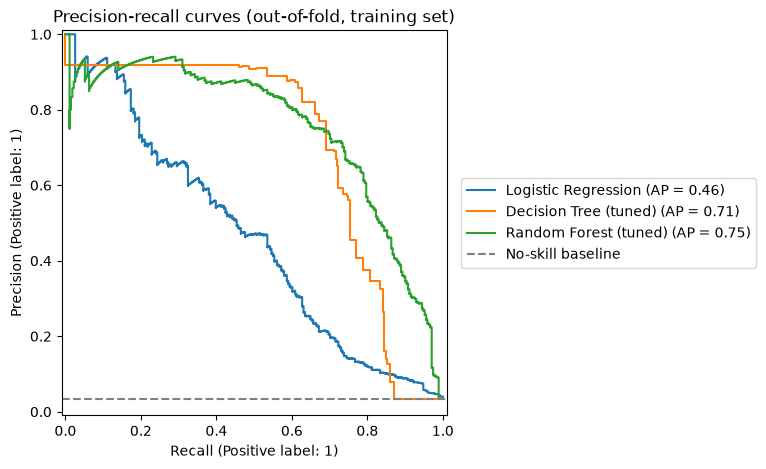

In [13]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import PrecisionRecallDisplay, ConfusionMatrixDisplay, average_precision_score

final_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree (tuned)": best_tree,
    "Random Forest (tuned)": best_rf,
}

oof_probs = {}
for name, model in final_models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    oof_probs[name] = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

fig, ax = plt.subplots(figsize=(9, 5))
for name, prob in oof_probs.items():
    PrecisionRecallDisplay.from_predictions(y_train, prob, name=name, ax=ax)
    print(f"{name}: pooled AP = {average_precision_score(y_train, prob):.3f}")
ax.axhline(y_train.mean(), color="grey", linestyle="--", label="No-skill baseline")
ax.set_title("Precision-recall curves (out-of-fold, training set)")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()

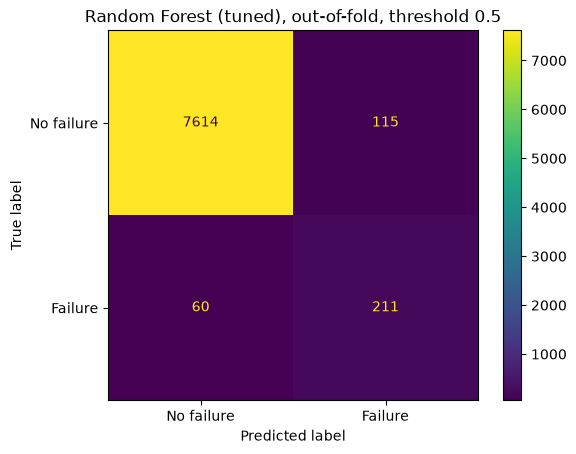

In [12]:
oof_pred_rf = (oof_probs["Random Forest (tuned)"] >= 0.5).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_train, oof_pred_rf, display_labels=["No failure", "Failure"]
)
plt.title("Random Forest (tuned), out-of-fold, threshold 0.5")
plt.show()

**Findings:**
- The Random Forest and Decision Tree curves are close until recall reaches about 0.7. After that the forest keeps its precision better. Both sit well above Logistic Regression and the no-skill line (0.034).
- Average precision on all out-of-fold predictions together is 0.749 for the forest, 0.705 for the tree and 0.459 for Logistic Regression.
- At threshold 0.5 the forest correctly flags 211 of 271 failures (recall 0.779) and misses 60. It raises 115 false alarms, so only 211 of its 326 failure predictions are right (precision 0.647).
- The 60 missed failures and 115 false alarms add up with the 7,614 and 211 correct predictions to all 8,000 training rows, as they should.
- Whether 60 misses or 115 false alarms is acceptable depends on the cost of an unplanned failure against an unnecessary inspection. The 0.5 threshold was not chosen for that trade-off, and I have not tuned it yet.

## 6. Error analysis

Where does the Random Forest go wrong? I label every training row as a caught failure, missed failure, false alarm or true negative using the out-of-fold predictions, then look at the failure modes it misses and at how the missed failures and false alarms differ from the rest.

In [14]:
errors = df.loc[X_train.index].copy()
errors["pred"] = oof_pred_rf
errors["outcome"] = "true negative"
errors.loc[(errors["Machine failure"] == 1) & (errors["pred"] == 1), "outcome"] = "caught failure"
errors.loc[(errors["Machine failure"] == 1) & (errors["pred"] == 0), "outcome"] = "missed failure"
errors.loc[(errors["Machine failure"] == 0) & (errors["pred"] == 1), "outcome"] = "false alarm"
print(errors["outcome"].value_counts())

failures = errors[errors["Machine failure"] == 1]
modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]

mode_rows = []
for m in modes:
    sub = failures[failures[m] == 1]
    mode_rows.append({"failure mode": m, "failures": len(sub),
                      "caught": int(sub["pred"].sum()), "recall": round(sub["pred"].mean(), 3)})
none = failures[failures[modes].sum(axis=1) == 0]
mode_rows.append({"failure mode": "no mode recorded", "failures": len(none),
                  "caught": int(none["pred"].sum()), "recall": round(none["pred"].mean(), 3)})

mode_table = pd.DataFrame(mode_rows).set_index("failure mode")
mode_table

outcome
true negative     7614
caught failure     211
false alarm        115
missed failure      60
Name: count, dtype: int64


,failures,caught,recall
failure mode,,,
TWF,36,3,0.083
HDF,86,84,0.977
PWF,82,74,0.902
OSF,82,71,0.866
RNF,1,0,0.000
no mode recorded,7,0,0.000


In [15]:
errors.groupby("outcome")[numeric_cols].mean().round(1)

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
outcome,,,,,
caught failure,301.1,310.4,1479.4,53.0,127.9
false alarm,301.0,310.5,1469.6,51.1,135.6
missed failure,300.2,310.2,1575.7,40.4,188.9
true negative,300.0,310.0,1541.8,39.5,106.1


**Findings:**
- The forest misses almost every tool wear failure (TWF): it catches 3 of 36 (recall 0.083). It catches 84 of 86 heat dissipation failures (0.977), 74 of 82 power failures (0.902) and 71 of 82 overstrain failures (0.866).
- TWF is the weak spot. The missed failures have high tool wear on average (188.9 min compared with 106.1 for true negatives), but this is not distinctive enough for the model to separate them reliably. I believe the dataset description says tool wear failures happen at a random wear value between 200 and 240 minutes, which I need to check against my data dictionary. If that is right, the exact failure time is partly random, so a model working from these features cannot predict it.
- The 7 failures with no recorded mode and the 1 random-failure (RNF) row are all missed. These are the label-noise cases found in the data audit, so this is not a model weakness.
- The missed failures look like normal rows on torque (40.4 Nm, against 39.5 for true negatives and 53.0 for caught failures). That fits with them being mostly tool wear failures, which do not depend on torque.
- The 115 false alarms resemble caught failures on torque (51.1 compared with 53.0), so they are normal rows under high load that the model reasonably flags.
- A failure can have more than one mode (22 of the failures do), so the failure mode counts above overlap and should not be added together.